# Exercise 5
Nico Reiterer - 5191 2112

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

## 5.1.)
Write a program that realizes the composite trapezoidal rule for integration on $[a,b]$. The rule is based on a subdivision of $[a,b]$ into N subintervals of length $h= (b−a)/N$. The inputs are a function handle for f, N, and a, b.

In [43]:
def comp_trap_rule(f: callable, N: int, a: float, b:float):
    """
        Realization of the composite trapezoidal rule for integration on [a,b]

        f: some function handle
        N: number of subintervals
        a, b: integration interval
    """

    h = (b - a) / N
    t = a + np.arange(1, N) * h   # interior nodes x_1, ..., x_{N-1}
    return h * (f(a)/2 + np.sum(f(t)) + f(b)/2)

f_1 = lambda x: x**2
f_2 = lambda x: np.abs(x)
f_3 = lambda x: np.where(x < 1/3, 0.5 * np.exp(x), np.exp(x))
f_4 = lambda x: np.sin(np.pi * x)
f_5 = lambda x: np.sin(4 * np.pi * x)

Exact integrals on $[-1,1]$:
- $\int_{-1}^1 x^2\,dx = \frac{2}{3}$
- $\int_{-1}^1 |x|\,dx = 1$
- $\int_{-1}^{1/3} \frac{1}{2}e^x\,dx + \int_{1/3}^1 e^x\,dx = \frac{1}{2}(e^{1/3} - e^{-1}) + (e - e^{1/3}) = e - \frac{1}{2}e^{1/3} - \frac{1}{2}e^{-1}$
- $\int_{-1}^1 \sin(\pi x)\,dx = \int_{-1}^1 \sin(4\pi x)\,dx = 0$ (odd functions)

In [44]:
a, b = -1, 1
fs = {"f_1": f_1, "f_2": f_2, "f_3": f_3, "f_4": f_4, "f_5": f_5}
exact = {
    "f_1": 2/3,
    "f_2": 1.0,
    "f_3": np.e - 0.5 * np.exp(1/3) - 0.5 * np.exp(-1),
    "f_4": 0.0,
    "f_5": 0.0,
}

i_vals = np.arange(1, 21)
N_vals = 2**i_vals
h_vals = (b - a) / N_vals

errors = pd.DataFrame(
    {name: [abs(comp_trap_rule(f, N, a, b) - exact[name]) for N in N_vals] for name, f in fs.items()},
    index=pd.Index(i_vals, name="i"),
)
errors.insert(0, "h", h_vals)
errors.insert(0, "N", N_vals)
errors

,N,h,f_1,f_2,f_3,f_4,f_5
i,,,,,,,
1,2,1.000000,3.333333e-01,0.0,1.145749e-01,0.000000e+00,0.000000e+00
2,4,0.500000,8.333333e-02,0.0,1.150128e-01,0.000000e+00,0.000000e+00
3,8,0.250000,2.083333e-02,0.0,1.461245e-02,2.775558e-17,0.000000e+00
4,16,0.125000,5.208333e-03,0.0,1.813104e-02,1.457168e-16,0.000000e+00
5,32,0.062500,1.302083e-03,0.0,6.367126e-03,5.724587e-17,6.245005e-17
6,64,0.031250,3.255208e-04,0.0,3.859447e-03,1.301043e-17,2.775558e-17
7,128,0.015625,8.138021e-05,0.0,1.760894e-03,5.421011e-19,1.387779e-17
8,256,0.007812,2.034505e-05,0.0,9.226732e-04,1.110223e-16,3.469447e-18
9,512,0.003906,5.086263e-06,0.0,4.507823e-04,1.110223e-16,3.295975e-17


In [45]:
# zeros are reported separately (log(0) is undefined)
for name in fs:
    zero_i = errors[np.isclose(errors[name], 0, atol=1e-12)].index.tolist()
    print(f"{name}: error exactly 0 for i = {zero_i if zero_i else 'none'}")

f_1: error exactly 0 for i = none
f_2: error exactly 0 for i = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
f_3: error exactly 0 for i = none
f_4: error exactly 0 for i = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
f_5: error exactly 0 for i = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


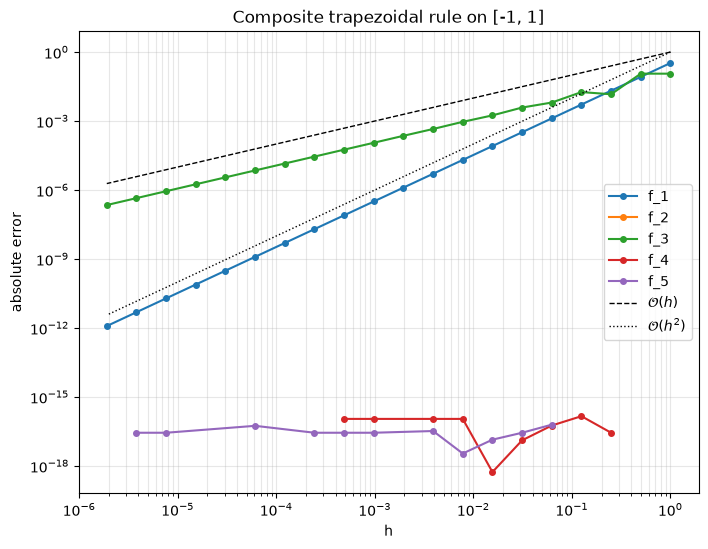

In [46]:
fig, ax = plt.subplots(figsize=(8, 6))
for name in fs:
    mask = errors[name] > 0
    ax.loglog(errors["h"][mask], errors[name][mask], "o-", ms=4, label=name)

# reference slopes
ax.loglog(h_vals, h_vals, "k--", lw=1, label=r"$\mathcal{O}(h)$")
ax.loglog(h_vals, h_vals**2, "k:", lw=1, label=r"$\mathcal{O}(h^2)$")

ax.set_xlabel("h")
ax.set_ylabel("absolute error")
ax.set_title("Composite trapezoidal rule on [-1, 1]")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

**Observations / Explanations:**
- $f_1$: From p.39 we know that if $f$ is a polynomial of degree $\geq 2$, then it is dependend on $h^2$ and the second derivative of $f$. And since the second derivative of $f_1 = x^2$ is constant, the error is proportional to $h^2$.
- $f_2$: For a linear interpolant the tripezoidal is exact as expected given Theorem 2.8.
- $f_3$: As we have this jump at x = 1/3, the trapezoidal rule will not be exact. The error is proportional to $h^2$ as well, but as shown on paper this one jump leads to an error that is proportional to $h$, which is in that sense the stronger error.
- $f_4$, $f_5$: They are odd functions, so the integral over a symmetric interval is zero. The trapezoidal rule will also yield zero, becaause the trapezoids cancel each other out in the same way. The error is zero, as expected. The error shown above is just due to computational inaccuracies.

## 5.3

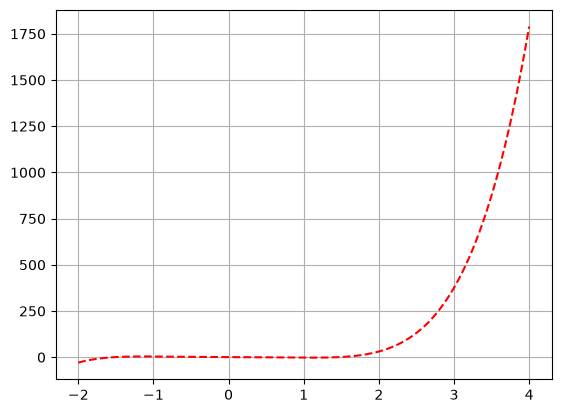

In [47]:
analytical_f = lambda x: 1 - x - 4 * x**3 + 2 * x**5
x_fine = np.linspace(-2, 4, 1000)
y = analytical_f(x_fine)

plt.plot(x_fine, y, "r--")
plt.grid(True)

In [67]:
def comp_simpson_rule(f: callable, N: int, a: float, b: float):
    """
        Composite Simpson rule on [a,b]

        f: some function handle
        N: number of subintervals (each with its own midpoint)
        a, b: integration interval
    """
    h = (b - a) / N
    x = a + np.arange(N + 1) * h      # nodes x_0, ..., x_N
    m = x[:-1] + h / 2                # midpoints m_0, ..., m_{N-1}
    return h / 6 * (f(a) + 2 * np.sum(f(x[1:-1])) + 4 * np.sum(f(m)) + f(b))

analytical_f_int = lambda x: x - x**2 / 2 - x**4 + x**6 / 3

In [73]:
print("Trapezoidal Rule:",
      "\nN = 1:", comp_trap_rule(analytical_f, 1, -2, 4),
      "\nN = 3:", comp_trap_rule(analytical_f, 3, -2, 4),
      "\nN = 4:", comp_trap_rule(analytical_f, 4, -2, 4))

print("\nSimpson Rule:",
      "\nN = 1:", comp_simpson_rule(analytical_f, 1, -2, 4),
      "\nN = 3:", comp_simpson_rule(analytical_f, 3, -2, 4),
      "\nN = 4:", comp_simpson_rule(analytical_f, 4, -2, 4))



Trapezoidal Rule: 
N = 1: 5280.0 
N = 3: 1824.0 
N = 4: 1516.875

Simpson Rule: 
N = 1: 1752.0 
N = 3: 1112.0 
N = 4: 1106.53125


In [58]:
# midpoint rule
print(2 * (analytical_f(-1) + analytical_f(1) + analytical_f(3)))

# midpoint without any composition
a, b = -2, 4
print((b - a) * analytical_f((a + b) / 2))

756
-12.0


In [62]:
print(analytical_f(-2) + 4 * analytical_f(1) + analytical_f(4))

1752


In [74]:
# Relative errors
rel_err = lambda I, Q: np.abs(I - Q) / np.abs(I)

# a)
print("a)", rel_err(1104, 5280))
# b)
print("b)", rel_err(1104, -12))

# c)
print("c)", rel_err(1104, 1752))

# d)
print("d)", rel_err(1104, 1516.875))

# e)
print("e)", rel_err(1104, 1112))


a) 3.782608695652174
b) 1.0108695652173914
c) 0.5869565217391305
d) 0.37398097826086957
e) 0.007246376811594203


## 5.4c) 

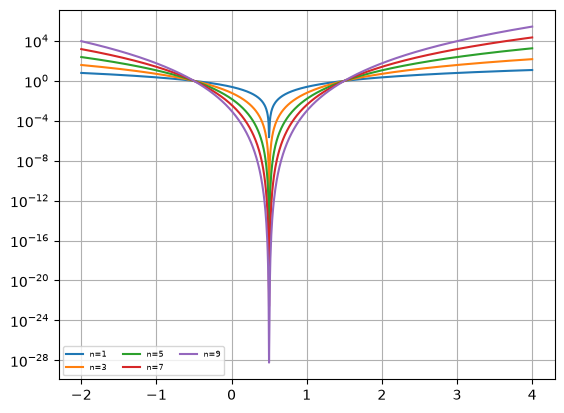

In [87]:
n = np.arange(1, 11, 2)                      # shape (51,)
x_fine = np.linspace(-2, 4, 1000)             # shape (1000,)

analytical_f = lambda x, n: (x - 0.5)**(n + 1)

# n as a column (51, 1), x as a row (1, 1000) -> result (51, 1000)
y = analytical_f(x_fine[None, :], n[:, None])
# row i of y is the curve for n[i]

plt.semilogy(x_fine, y.T)      # plt.plot draws each COLUMN as a line, so transpose
plt.legend([f"n={k}" for k in n], ncol=3, fontsize=6)
plt.grid(True)
plt.show()


In [ ]:
##

## 5.5. Neville Scheme for Romberg extrapolation

In [88]:
def N(f: np.ndarray, x: np.ndarray, x_dash: float) -> np.ndarray:
    """
    Algorithm 1 (Aitken-Neville Scheme) from p.5 of the script

        f: vector f ∈ Rn+
        x: knot vector x ∈ Rn+1
    
    """
    n = len(x)
    N = np.zeros((n, n)) # or rather np.full((n, n), np.nan) because zero could be a value ofc
    N[:,0] = f

    for m in range(1, n):
        for j in range(0, n - m):
            p_jm = (x_dash - x[j]) * N[j + 1, m - 1] - (x_dash - x[j+m]) * N[j, m - 1]
            p_jm /= (x[j+m] - x[j])
            N[j, m] =  p_jm
    
    return N